# Principal Component Analysis (PCA)

PCA on correlated bivariate data and on the Iris dataset: principal directions, projections onto PC1/PC2, 2-D visualization of the species and explained variance.


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn import datasets
from sklearn.preprocessing import StandardScaler

In [4]:
np.random.seed(42)
mean = [0, 0]
cov = [[3, 2], [2, 2]]
X = np.random.multivariate_normal(mean=mean, cov=cov, size=200)

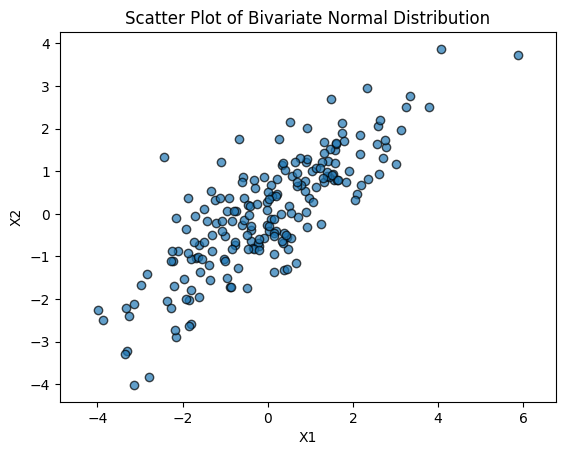

In [6]:
# Scatter plot of the two features
plt.figure()
plt.scatter(X[:, 0], X[:, 1], edgecolor='k', alpha=0.7)
plt.title("Scatter Plot of Bivariate Normal Distribution")
plt.xlabel("X1")
plt.ylabel("X2")
plt.axis('equal')
plt.show()


X1 and X2 are strongly and positively correlated. The points form a tilted ellipse running from bottom-left to top-right. When X1 increases, X2 tends to increase too.

The relationship is strong and linear (r ≈ 0.8). This matches the covariance matrix the lab uses, [[3, 2], [2, 2]], which gives r = 2/√(3·2) ≈ 0.82.
X1 is more spread out than X2. X1 ranges from about −4 to 6 (variance 3), while X2 ranges from about −4 to 4 (variance 2).
The cloud is centred at (0, 0), which matches the mean of [0, 0].
There are no real outliers. The few points at the ends, such as (6, 3.7) and (4, 3.9), are normal tails of a Gaussian distribution.
What this means for PCA
The long axis of the ellipse is the first principal component (PC1). It points roughly along the diagonal, at about 38° from the X1 axis, because X1 has more variance.
With these values, PC1 captures about 91% of the total variance (eigenvalues ≈ 4.56 and 0.44). PC2, the short axis, keeps only about 9%.
So the two features contain mostly redundant information. You can reduce them to one dimension (PC1) and lose very little information. That is exactly what the lab demonstrates next, when you project the points onto PC1.

In [7]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

In [8]:
components = pca.components_
components

array([[ 0.78215821,  0.62307987],
       [-0.62307987,  0.78215821]])

In [9]:
pca.explained_variance_ratio_

array([0.9111946, 0.0888054])

In [10]:
projection_pc1 = np.dot(X, components[0])
projection_pc2 = np.dot(X, components[1])

In [11]:
x_pc1 = projection_pc1 * components[0][0]
y_pc1 = projection_pc1 * components[0][1]
x_pc2 = projection_pc2 * components[1][0]
y_pc2 = projection_pc2 * components[1][1]

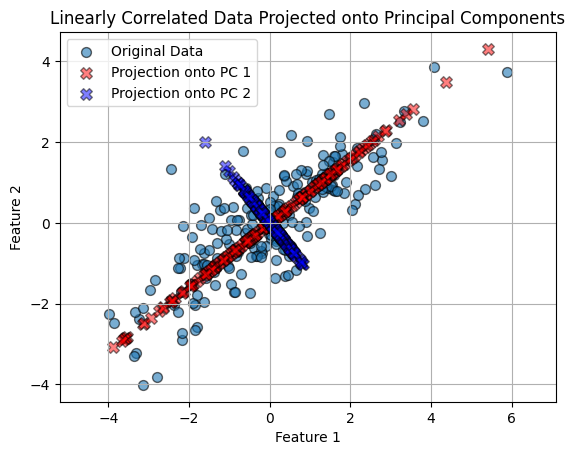

In [12]:
# Plot original data
plt.figure()
plt.scatter(X[:, 0], X[:, 1], label='Original Data', ec='k', s=50, alpha=0.6)

# Plot the projections along PC1 and PC2
plt.scatter(x_pc1, y_pc1, c='r', ec='k', marker='X', s=70, alpha=0.5, label='Projection onto PC 1')
plt.scatter(x_pc2, y_pc2, c='b', ec='k', marker='X', s=70, alpha=0.5, label='Projection onto PC 2')
plt.title('Linearly Correlated Data Projected onto Principal Components', )
plt.xlabel('Feature 1',)
plt.ylabel('Feature 2',)
plt.legend()
plt.grid(True)
plt.axis('equal')
plt.show()

PC1 (red) follows the long axis of the data. The red projections stretch along the diagonal from about (−4, −3) to (5.4, 4.3), a slope of about 0.8, or roughly 38°. This is the direction of maximum variance, and it matches the expected PC1.
PC2 (blue) is short and perpendicular to PC1. The blue projections only cover from about (−1.6, 2) to (0.8, −1), so the spread along PC2 is small. This is the variance that PC1 doesn't explain.
The spread confirms the variance split. The red line is about 3× longer than the blue one, which fits standard deviations of √4.56 ≈ 2.1 vs √0.44 ≈ 0.66. In variance terms, that is about 91% for PC1 and about 9% for PC2.
The two axes are orthogonal. PCA rotates the coordinate system so the new axes are uncorrelated. The blue line looks slightly off 90° only because the plot's axes don't use the same scale. Adding plt.axis('equal') shows the true right angle.
The projections are centred at (0, 0). PCA centres the data on its mean before finding the components.
Takeaway
You can replace the two original features with just PC1 and keep about 91% of the information. Each point is then described by one number, its position along the red line, instead of two. The original features are highly redundant: they measure essentially the same underlying factor.

This is the point of PCA for dimensionality reduction. With many correlated features, such as the 28 PCA components in the fraud dataset, a few principal components can summarise most of the variance. That makes models faster and less prone to overfitting.

In [13]:
# Load the Iris dataset
iris = datasets.load_iris()
X = iris.data
y = iris.target
target_names = iris.target_names

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [14]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [16]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

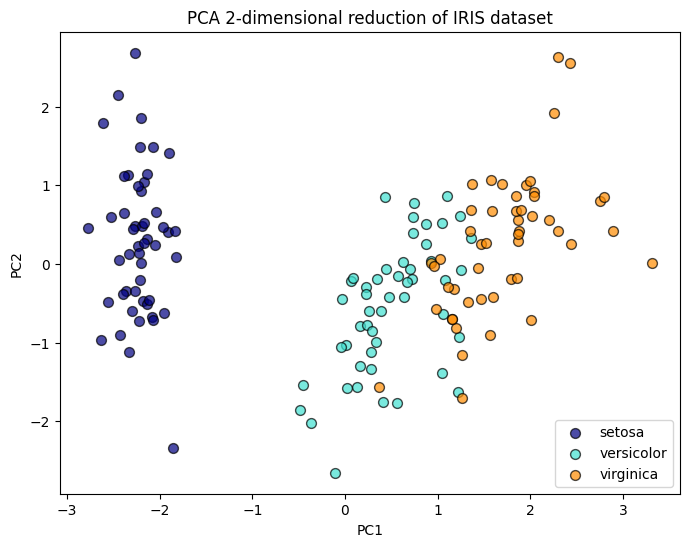

In [17]:
plt.figure(figsize=(8,6))

colors = ['navy', 'turquoise', 'darkorange']
lw = 1

for color, i, target_name in zip(colors, [0, 1, 2], target_names):
    plt.scatter(X_pca[y == i, 0], X_pca[y == i, 1], color=color, s=50, ec='k',alpha=0.7, lw=lw,
                label=target_name)

plt.title('PCA 2-dimensional reduction of IRIS dataset',)
plt.xlabel("PC1",)
plt.ylabel("PC2",)
plt.legend(loc='best', shadow=False, scatterpoints=1,)
# plt.grid(True)
plt.show()

In [18]:

100*pca.explained_variance_ratio_.sum()

np.float64(95.81320720000166)

In [19]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

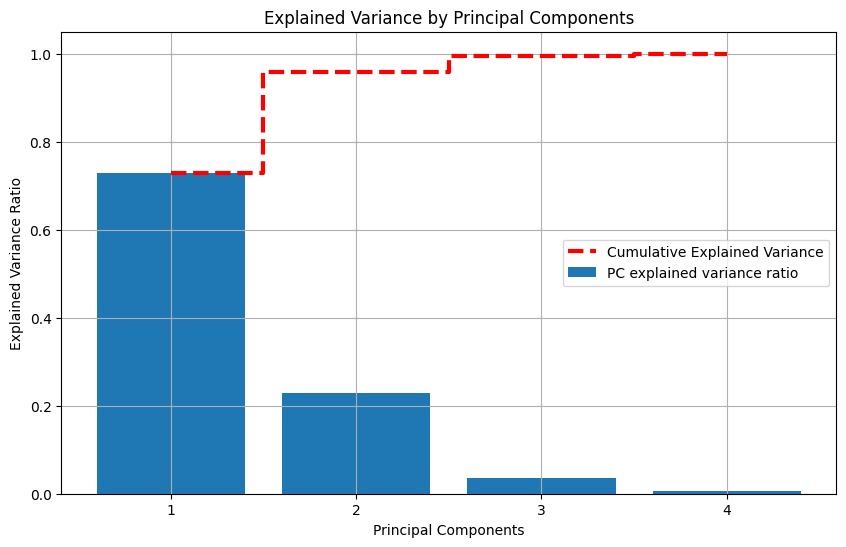

In [20]:
explained_variance_ratio = pca.explained_variance_ratio_

# Plot explained variance ratio for each component
plt.figure(figsize=(10,6))
plt.bar(x=range(1, len(explained_variance_ratio)+1), height=explained_variance_ratio, alpha=1, align='center', label='PC explained variance ratio' )
plt.ylabel('Explained Variance Ratio')
plt.xlabel('Principal Components')
plt.title('Explained Variance by Principal Components')

# Plot cumulative explained variance
cumulative_variance = np.cumsum(explained_variance_ratio)
plt.step(range(1, 5), cumulative_variance, where='mid', linestyle='--', lw=3,color='red', label='Cumulative Explained Variance')
# Only display integer ticks on the x-axis
plt.xticks(range(1, 5))
plt.legend()
plt.grid(True)
plt.show()

PC1 dominates. On its own it captures almost three quarters of the variation across the 4 measurements. This is the "flower size" axis, driven by petal length, petal width and sepal length.
PC2 adds most of what's left. Together, PC1 and PC2 explain about 96%. The cumulative line jumps sharply at PC2 and then flattens.
PC3 and PC4 add almost nothing. Together they hold about 4%, mostly small measurement variation and noise.
The elbow is at PC2. After the second component, each extra one adds very little. That makes 2 the natural number of components to keep.